In [2]:
# ============================================================
# TASK 5 — PREDICTIVE STATISTICAL MODELLING
# ============================================================

# Import the main libraries needed for data preparation.

import pandas as pd
import numpy as np

# Mount Google Drive so the cleaned transaction dataset can be accessed.

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
# # Task 5 — Predictive Statistical Modelling

# ## Objective

# The objective of this section is to predict whether an existing customer
# will make another purchase in a future period using only their historical
# purchasing behaviour.

# The target variable is:

# - `RepeatPurchase = 1` if the customer purchases again in the future period.
# - `RepeatPurchase = 0` if the customer does not purchase again.

# Two predictive models will be compared:

# 1. Standard Logistic Regression
# 2. Ridge Logistic Regression

# Historical customer features are created only from transactions that occurred
# before the future prediction period to prevent data leakage.

In [4]:
# ============================================================
# 2. LOAD THE MERCHANDISE TRANSACTION DATA
# ============================================================

import os

# Set the folder path where your cleaned datasets are stored.
base_path = "/content/drive/MyDrive/Statistical Modelling Project/02_Clean_Data/"

# Check the files inside the folder first.
# This helps us confirm the exact filename before loading the dataset.
print(os.listdir(base_path))

# Load the merchandise-level transaction dataset.
#
# We use this dataset because Task 5 requires us to rebuild
# customer features from historical transactions only.
df_merchandise = pd.read_csv(
    base_path + "online_retail_merchandise"
)

# Convert InvoiceDate into datetime format.
# This is necessary because we will split transactions into
# historical and future periods based on date.
df_merchandise["InvoiceDate"] = pd.to_datetime(
    df_merchandise["InvoiceDate"]
)

# Check that the dataset loaded correctly.
print("\nDataset shape:", df_merchandise.shape)

print("\nDate range:")
print("Minimum date:", df_merchandise["InvoiceDate"].min())
print("Maximum date:", df_merchandise["InvoiceDate"].max())

print("\nFirst 5 rows:")
print(df_merchandise.head())

['online_retail_clean', 'online_retail_merchandise', 'order_level_data', 'customer_level_data']

Dataset shape: (776928, 10)

Date range:
Minimum date: 2009-12-01 07:45:00
Maximum date: 2011-12-09 12:50:00

First 5 rows:
   Invoice StockCode                          Description  Quantity  \
0   489434     85048  15CM CHRISTMAS GLASS BALL 20 LIGHTS        12   
1   489434    79323P                   PINK CHERRY LIGHTS        12   
2   489434    79323W                  WHITE CHERRY LIGHTS        12   
3   489434     22041         RECORD FRAME 7" SINGLE SIZE         48   
4   489434     21232       STRAWBERRY CERAMIC TRINKET BOX        24   

          InvoiceDate  Price  Customer ID         Country SourceYear  \
0 2009-12-01 07:45:00   6.95      13085.0  United Kingdom  2009-2010   
1 2009-12-01 07:45:00   6.75      13085.0  United Kingdom  2009-2010   
2 2009-12-01 07:45:00   6.75      13085.0  United Kingdom  2009-2010   
3 2009-12-01 07:45:00   2.10      13085.0  United Kingdom  2009-

In [5]:
# ============================================================
# 3. DEFINE HISTORICAL AND FUTURE PERIODS
# ============================================================

# The historical observation period is used to create customer features.
# These are the behaviours that would already be known at prediction time.

observation_start = pd.Timestamp("2010-06-10")
observation_end = pd.Timestamp("2011-06-09 23:59:59")

# The future outcome period comes after the historical period.
# It is used only to determine whether the customer purchased again.

outcome_start = pd.Timestamp("2011-06-10")
outcome_end = pd.Timestamp("2011-12-09 23:59:59")

print("Historical period:")
print(observation_start, "to", observation_end)

print("\nFuture period:")
print(outcome_start, "to", outcome_end)

Historical period:
2010-06-10 00:00:00 to 2011-06-09 23:59:59

Future period:
2011-06-10 00:00:00 to 2011-12-09 23:59:59


In [6]:
# ============================================================
# 4. SPLIT TRANSACTIONS INTO HISTORICAL AND FUTURE DATA
# ============================================================

# Historical data:
# Used to create predictor variables such as Frequency, Recency,
# Average Order Value, Product Diversity, etc.

df_history = df_merchandise[
    (df_merchandise["InvoiceDate"] >= observation_start) &
    (df_merchandise["InvoiceDate"] <= observation_end)
].copy()

# Future data:
# Used only to determine whether a customer purchases again.

df_future = df_merchandise[
    (df_merchandise["InvoiceDate"] >= outcome_start) &
    (df_merchandise["InvoiceDate"] <= outcome_end)
].copy()

print("Historical rows:", len(df_history))
print("Future rows:", len(df_future))

print("\nHistorical date range:")
print(df_history["InvoiceDate"].min())
print(df_history["InvoiceDate"].max())

print("\nFuture date range:")
print(df_future["InvoiceDate"].min())
print(df_future["InvoiceDate"].max())

Historical rows: 366482
Future rows: 238954

Historical date range:
2010-06-10 08:47:00
2011-06-09 20:03:00

Future date range:
2011-06-10 08:24:00
2011-12-09 12:50:00


In [7]:
# ============================================================
# 5. IDENTIFY ELIGIBLE HISTORICAL CUSTOMERS
# ============================================================

# We can only predict future behaviour for customers who already
# existed during the historical observation period.
#
# Therefore, only customers appearing in df_history are eligible.

historical_customers = (
    df_history["Customer ID"]
    .dropna()
    .unique()
)

print("Eligible historical customers:", len(historical_customers))

Eligible historical customers: 4324


In [8]:
# ============================================================
# 6. CREATE REPEAT-PURCHASE TARGET
# ============================================================

# Find all customers who purchased during the future period.

future_customers = set(
    df_future["Customer ID"]
    .dropna()
    .unique()
)

# Create one modelling row for every historical customer.

df_model = pd.DataFrame({
    "CustomerID": historical_customers
})

# RepeatPurchase = 1:
# customer appears again in the future period.
#
# RepeatPurchase = 0:
# customer does not appear in the future period.

df_model["RepeatPurchase"] = (
    df_model["CustomerID"]
    .isin(future_customers)
    .astype(int)
)

print(df_model.head())

print("\nTarget counts:")
print(df_model["RepeatPurchase"].value_counts())

print("\nTarget percentages:")
print(
    df_model["RepeatPurchase"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

   CustomerID  RepeatPurchase
0     13709.0               1
1     16206.0               1
2     13446.0               0
3     12727.0               1
4     18219.0               1

Target counts:
RepeatPurchase
1    2481
0    1843
Name: count, dtype: int64

Target percentages:
RepeatPurchase
1    57.38
0    42.62
Name: proportion, dtype: float64


In [9]:
# ============================================================
# 7. CREATE HISTORICAL ORDER-LEVEL DATA
# ============================================================

# The merchandise dataset has one row per product line.
#
# However, Frequency should represent the number of ORDERS,
# not the number of individual product rows.
#
# Therefore, we first combine product lines belonging to the
# same invoice into one order.

history_orders = (
    df_history
    .groupby("Invoice", as_index=False)
    .agg(
        CustomerID=("Customer ID", "first"),
        OrderDate=("InvoiceDate", "min"),
        OrderValue=("TransactionValue", "sum"),
        UniqueProducts=("StockCode", "nunique")
    )
)

print("Historical orders:", len(history_orders))
print("Historical customers:", history_orders["CustomerID"].nunique())

print("\nFirst 5 historical orders:")
print(history_orders.head())

Historical orders: 17833
Historical customers: 4324

First 5 historical orders:
   Invoice  CustomerID           OrderDate  OrderValue  UniqueProducts
0   511700     13709.0 2010-06-10 08:47:00      283.44              13
1   511701     16206.0 2010-06-10 09:17:00      313.38              19
2   511702     13446.0 2010-06-10 09:22:00      303.38              19
3   511703     12727.0 2010-06-10 09:40:00      462.43              20
4   511704     18219.0 2010-06-10 09:55:00      193.10              13


In [10]:
# ============================================================
# 8. CREATE MAIN HISTORICAL CUSTOMER FEATURES
# ============================================================

# We now convert the historical order-level data into
# one row per customer.
#
# These variables describe customer behaviour BEFORE
# the future prediction period.

historical_features = (
    history_orders
    .groupby("CustomerID")
    .agg(
        # Number of historical orders.
        Frequency=("Invoice", "nunique"),

        # Total amount spent during the historical period.
        Monetary=("OrderValue", "sum"),

        # Typical value of one order.
        AverageOrderValue=("OrderValue", "mean"),

        # First observed historical purchase.
        FirstPurchaseDate=("OrderDate", "min"),

        # Most recent historical purchase.
        LastPurchaseDate=("OrderDate", "max")
    )
    .reset_index()
)

print("Historical customer feature rows:", len(historical_features))
print(historical_features.head())

Historical customer feature rows: 4324
   CustomerID  Frequency  Monetary  AverageOrderValue   FirstPurchaseDate  \
0     12346.0          2  77325.91          38662.955 2010-06-28 13:53:00   
1     12347.0          5   2817.48            563.496 2010-10-31 14:20:00   
2     12348.0          4   1388.40            347.100 2010-09-27 14:59:00   
3     12349.0          1   1152.62           1152.620 2010-10-28 08:23:00   
4     12350.0          1    294.40            294.400 2011-02-02 16:01:00   

     LastPurchaseDate  
0 2011-01-18 10:01:00  
1 2011-06-09 13:01:00  
2 2011-04-05 10:47:00  
3 2010-10-28 08:23:00  
4 2011-02-02 16:01:00  


In [11]:
# ============================================================
# 9. CREATE RECENCY AND CUSTOMER TENURE
# ============================================================

# The reference date is the first day of the future period.
# This represents the point at which we would make the prediction.

reference_date = pd.Timestamp("2011-06-10")

# Recency:
# Number of days since the customer's most recent purchase.
#
# Smaller Recency = customer purchased more recently.

historical_features["Recency"] = (
    reference_date - historical_features["LastPurchaseDate"]
).dt.days


# CustomerTenure:
# Number of days between first and most recent historical purchase.
#
# This represents the length of the customer's observed
# relationship with the retailer.

historical_features["CustomerTenure"] = (
    historical_features["LastPurchaseDate"] -
    historical_features["FirstPurchaseDate"]
).dt.days

print(
    historical_features[
        ["CustomerID", "Recency", "CustomerTenure"]
    ].head()
)

   CustomerID  Recency  CustomerTenure
0     12346.0      142             203
1     12347.0        0             220
2     12348.0       65             189
3     12349.0      224               0
4     12350.0      127               0


In [12]:
# ============================================================
# 10. CREATE PRODUCT DIVERSITY
# ============================================================

# ProductDiversity measures how many different products
# the customer purchased during the historical period.
#
# It helps represent the breadth of customer engagement.

product_diversity = (
    df_history
    .groupby("Customer ID")["StockCode"]
    .nunique()
    .reset_index(name="ProductDiversity")
)

product_diversity = product_diversity.rename(
    columns={"Customer ID": "CustomerID"}
)

historical_features = historical_features.merge(
    product_diversity,
    on="CustomerID",
    how="left"
)

print(
    historical_features[
        ["CustomerID", "ProductDiversity"]
    ].head()
)

   CustomerID  ProductDiversity
0     12346.0                20
1     12347.0               101
2     12348.0                24
3     12349.0                54
4     12350.0                16


In [13]:
# ============================================================
# 11. CREATE AVERAGE PURCHASE INTERVAL
# ============================================================

# AveragePurchaseInterval represents the average number of days
# between consecutive orders.
#
# It helps describe how regularly a customer purchases.
#
# Customers with only one historical order will naturally have
# no purchase interval, so their value will be missing for now.

def calculate_purchase_interval(group):

    # Sort orders chronologically.
    dates = group["OrderDate"].sort_values()

    # Calculate days between consecutive orders.
    intervals = dates.diff().dt.days.dropna()

    # If the customer has only one order,
    # there is no purchase interval to calculate.
    if len(intervals) == 0:
        return np.nan

    return intervals.mean()


purchase_interval = (
    history_orders
    .groupby("CustomerID")
    .apply(calculate_purchase_interval)
    .reset_index(name="AveragePurchaseInterval")
)

historical_features = historical_features.merge(
    purchase_interval,
    on="CustomerID",
    how="left"
)

print(
    historical_features[
        ["CustomerID", "Frequency", "AveragePurchaseInterval"]
    ].head(10)
)

   CustomerID  Frequency  AveragePurchaseInterval
0     12346.0          2                   203.00
1     12347.0          5                    54.75
2     12348.0          4                    63.00
3     12349.0          1                      NaN
4     12350.0          1                      NaN
5     12351.0          1                      NaN
6     12352.0          6                    25.80
7     12353.0          2                   204.00
8     12354.0          1                      NaN
9     12355.0          1                      NaN


/tmp/ipykernel_1056/2010260792.py:32: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(calculate_purchase_interval)


In [14]:
# ============================================================
# 12. MERGE HISTORICAL FEATURES WITH FUTURE TARGET
# ============================================================

# df_model currently contains:
# CustomerID + RepeatPurchase
#
# historical_features contains customer behaviour from the past.
#
# We merge them to form the final modelling table.

df_model = df_model.merge(
    historical_features,
    on="CustomerID",
    how="left"
)

print("Modelling dataset shape:", df_model.shape)

print("\nColumns:")
print(df_model.columns.tolist())

print("\nFirst 5 rows:")
print(df_model.head())

Modelling dataset shape: (4324, 11)

Columns:
['CustomerID', 'RepeatPurchase', 'Frequency', 'Monetary', 'AverageOrderValue', 'FirstPurchaseDate', 'LastPurchaseDate', 'Recency', 'CustomerTenure', 'ProductDiversity', 'AveragePurchaseInterval']

First 5 rows:
   CustomerID  RepeatPurchase  Frequency  Monetary  AverageOrderValue  \
0     13709.0               1          4   1230.11         307.527500   
1     16206.0               1          9   1873.31         208.145556   
2     13446.0               0          4   1408.63         352.157500   
3     12727.0               1          7   3235.91         462.272857   
4     18219.0               1          9   1747.30         194.144444   

    FirstPurchaseDate    LastPurchaseDate  Recency  CustomerTenure  \
0 2010-06-10 08:47:00 2011-01-28 14:57:00      132             232   
1 2010-06-10 09:17:00 2011-05-15 11:04:00       25             339   
2 2010-06-10 09:22:00 2010-10-05 18:51:00      247             117   
3 2010-06-10 09:40:00 20

In [15]:
# ============================================================
# 13. CHECK MISSING VALUES
# ============================================================

# AveragePurchaseInterval is expected to contain missing values
# for customers who made only one historical order.

print(df_model.isnull().sum())

CustomerID                    0
RepeatPurchase                0
Frequency                     0
Monetary                      0
AverageOrderValue             0
FirstPurchaseDate             0
LastPurchaseDate              0
Recency                       0
CustomerTenure                0
ProductDiversity              0
AveragePurchaseInterval    1558
dtype: int64


In [16]:
# ============================================================
# 14. HANDLE MISSING AVERAGE PURCHASE INTERVAL
# ============================================================

# A missing AveragePurchaseInterval usually means the customer
# made only one historical purchase.
#
# This is meaningful information, not bad data.
#
# Therefore:
# 1. Create an indicator showing whether a purchase interval exists.
# 2. Replace missing interval values with 0 so the model can use the column.

df_model["HasPurchaseInterval"] = (
    df_model["AveragePurchaseInterval"]
    .notna()
    .astype(int)
)

df_model["AveragePurchaseInterval"] = (
    df_model["AveragePurchaseInterval"]
    .fillna(0)
)

print("Remaining missing values:")
print(df_model.isnull().sum())

Remaining missing values:
CustomerID                 0
RepeatPurchase             0
Frequency                  0
Monetary                   0
AverageOrderValue          0
FirstPurchaseDate          0
LastPurchaseDate           0
Recency                    0
CustomerTenure             0
ProductDiversity           0
AveragePurchaseInterval    0
HasPurchaseInterval        0
dtype: int64


In [17]:
# ============================================================
# 15. SELECT PREDICTORS AND TARGET
# ============================================================

predictor_cols = [
    "Frequency",
    "Recency",
    "AverageOrderValue",
    "ProductDiversity",
    "CustomerTenure",
    "AveragePurchaseInterval",
    "HasPurchaseInterval"
]

X = df_model[predictor_cols].copy()
y = df_model["RepeatPurchase"].copy()

print("Predictor shape:", X.shape)
print("Target shape:", y.shape)

print("\nPredictors:")
print(X.columns.tolist())

Predictor shape: (4324, 7)
Target shape: (4324,)

Predictors:
['Frequency', 'Recency', 'AverageOrderValue', 'ProductDiversity', 'CustomerTenure', 'AveragePurchaseInterval', 'HasPurchaseInterval']


In [18]:
# ============================================================
# 16. CHECK PREDICTOR SKEWNESS
# ============================================================

# Strong positive skewness means a small number of customers
# have very large values.
#
# We inspect skewness before deciding which predictors should
# be transformed.

skewness = X.skew().sort_values(ascending=False)

print("Predictor skewness:")
print(skewness)

Predictor skewness:
AverageOrderValue          32.590590
Frequency                  10.392495
ProductDiversity            6.382473
AveragePurchaseInterval     1.942671
CustomerTenure              0.568124
Recency                     0.401472
HasPurchaseInterval        -0.582114
dtype: float64


In [19]:
# ============================================================
# 17. CHECK CORRELATION BETWEEN PREDICTORS
# ============================================================

# Strongly correlated predictors can create multicollinearity.
#
# We inspect pairwise correlations before finalizing the model.

correlation_matrix = X.corr()

print(correlation_matrix.round(2))

                         Frequency  Recency  AverageOrderValue  \
Frequency                     1.00    -0.33               0.05   
Recency                      -0.33     1.00              -0.03   
AverageOrderValue             0.05    -0.03               1.00   
ProductDiversity              0.68    -0.32               0.10   
CustomerTenure                0.51    -0.66               0.05   
AveragePurchaseInterval      -0.03    -0.37               0.04   
HasPurchaseInterval           0.32    -0.45               0.03   

                         ProductDiversity  CustomerTenure  \
Frequency                            0.68            0.51   
Recency                             -0.32           -0.66   
AverageOrderValue                    0.10            0.05   
ProductDiversity                     1.00            0.48   
CustomerTenure                       0.48            1.00   
AveragePurchaseInterval              0.05            0.55   
HasPurchaseInterval                  0.35   

In [20]:
# ============================================================
# 18. LOG-TRANSFORM SKEWED PREDICTORS
# ============================================================

# Several predictors are strongly right-skewed.
#
# We use log1p(x) = log(1 + x) because it reduces the influence
# of extremely large values and also works when values can be zero.

df_model["Log_Frequency"] = np.log1p(
    df_model["Frequency"]
)

df_model["Log_AverageOrderValue"] = np.log1p(
    df_model["AverageOrderValue"]
)

df_model["Log_ProductDiversity"] = np.log1p(
    df_model["ProductDiversity"]
)

df_model["Log_AveragePurchaseInterval"] = np.log1p(
    df_model["AveragePurchaseInterval"]
)

# Check whether the transformations reduced skewness.

print(
    df_model[
        [
            "Log_Frequency",
            "Log_AverageOrderValue",
            "Log_ProductDiversity",
            "Log_AveragePurchaseInterval"
        ]
    ].skew()
)

Log_Frequency                  1.237300
Log_AverageOrderValue         -0.059222
Log_ProductDiversity          -0.282662
Log_AveragePurchaseInterval   -0.209733
dtype: float64


In [21]:
# ============================================================
# 19. DEFINE FINAL PREDICTOR SET
# ============================================================

# We use transformed versions of strongly skewed variables.
# Recency and CustomerTenure remain on their original scale.
# HasPurchaseInterval remains binary.

final_predictors = [
    "Log_Frequency",
    "Recency",
    "Log_AverageOrderValue",
    "Log_ProductDiversity",
    "CustomerTenure",
    "Log_AveragePurchaseInterval",
    "HasPurchaseInterval"
]

X = df_model[final_predictors].copy()
y = df_model["RepeatPurchase"].copy()

print("Final predictors:")
print(X.columns.tolist())

print("\nShape of X:", X.shape)
print("Shape of y:", y.shape)

print("\nMissing values:")
print(X.isnull().sum())

Final predictors:
['Log_Frequency', 'Recency', 'Log_AverageOrderValue', 'Log_ProductDiversity', 'CustomerTenure', 'Log_AveragePurchaseInterval', 'HasPurchaseInterval']

Shape of X: (4324, 7)
Shape of y: (4324,)

Missing values:
Log_Frequency                  0
Recency                        0
Log_AverageOrderValue          0
Log_ProductDiversity           0
CustomerTenure                 0
Log_AveragePurchaseInterval    0
HasPurchaseInterval            0
dtype: int64


In [22]:
# ============================================================
# 20. TRAIN / TEST SPLIT
# ============================================================

from sklearn.model_selection import train_test_split

# 80% of customers are used for training.
# 20% are held out for model evaluation.
#
# stratify=y keeps the RepeatPurchase proportions similar
# in both training and testing sets.

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training customers:", X_train.shape[0])
print("Testing customers:", X_test.shape[0])

print("\nTraining target percentages:")
print(
    y_train.value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nTesting target percentages:")
print(
    y_test.value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Training customers: 3459
Testing customers: 865

Training target percentages:
RepeatPurchase
1    57.39
0    42.61
Name: proportion, dtype: float64

Testing target percentages:
RepeatPurchase
1    57.34
0    42.66
Name: proportion, dtype: float64


In [23]:
# ============================================================
# 21. STANDARDIZE THE PREDICTORS
# ============================================================

from sklearn.preprocessing import StandardScaler

# Standardization is important because the predictors are
# measured on different scales.
#
# It is especially important for Ridge Logistic Regression.

scaler = StandardScaler()

# Fit the scaler only on training data to prevent data leakage.
X_train_scaled = scaler.fit_transform(X_train)

# Apply the same scaling to test data.
X_test_scaled = scaler.transform(X_test)

print("Scaled training shape:", X_train_scaled.shape)
print("Scaled testing shape:", X_test_scaled.shape)

Scaled training shape: (3459, 7)
Scaled testing shape: (865, 7)


**Standarad Logistic Regression**

In [24]:
# ============================================================
# 22. TRAIN STANDARD LOGISTIC REGRESSION
# ============================================================

from sklearn.linear_model import LogisticRegression

# Logistic Regression is suitable because RepeatPurchase is binary:
# 1 = customer purchases again in the future
# 0 = customer does not purchase again
#
# We first train a standard Logistic Regression model
# without regularization so it can act as our baseline model.

logistic_model = LogisticRegression(
    penalty=None,
    max_iter=1000
)

# Train the model using only the training customers.
logistic_model.fit(
    X_train_scaled,
    y_train
)

print("Standard Logistic Regression trained successfully.")

Standard Logistic Regression trained successfully.


In [25]:
# ============================================================
# 23. MAKE PREDICTIONS
# ============================================================

# Predict the final class for each unseen test customer.
#
# Output:
# 0 = predicted not to purchase again
# 1 = predicted to purchase again

y_pred_logistic = logistic_model.predict(
    X_test_scaled
)

# Predict probability of RepeatPurchase = 1.
#
# These probabilities are useful because they show
# how strongly the model believes a customer will return.

y_prob_logistic = logistic_model.predict_proba(
    X_test_scaled
)[:, 1]

print("Predictions completed.")

Predictions completed.


In [26]:
# ============================================================
# 24. EVALUATE STANDARD LOGISTIC REGRESSION
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# Accuracy:
# Overall percentage of correct predictions.
accuracy_logistic = accuracy_score(
    y_test,
    y_pred_logistic
)

# Precision:
# Among customers predicted to return,
# how many actually returned?
precision_logistic = precision_score(
    y_test,
    y_pred_logistic
)

# Recall:
# Among customers who actually returned,
# how many did the model successfully identify?
recall_logistic = recall_score(
    y_test,
    y_pred_logistic
)

# F1-score:
# Balances Precision and Recall.
f1_logistic = f1_score(
    y_test,
    y_pred_logistic
)

# ROC-AUC:
# Measures how well the model separates repeat
# customers from non-repeat customers across different thresholds.
auc_logistic = roc_auc_score(
    y_test,
    y_prob_logistic
)

print("Standard Logistic Regression Performance")
print("----------------------------------------")
print("Accuracy :", round(accuracy_logistic, 4))
print("Precision:", round(precision_logistic, 4))
print("Recall   :", round(recall_logistic, 4))
print("F1-score :", round(f1_logistic, 4))
print("ROC-AUC  :", round(auc_logistic, 4))

Standard Logistic Regression Performance
----------------------------------------
Accuracy : 0.696
Precision: 0.7432
Recall   : 0.7177
F1-score : 0.7303
ROC-AUC  : 0.7569


In [27]:
# ============================================================
# 25. CONFUSION MATRIX
# ============================================================

cm_logistic = confusion_matrix(
    y_test,
    y_pred_logistic
)

print("Confusion Matrix:")
print(cm_logistic)

Confusion Matrix:
[[246 123]
 [140 356]]


**Ridge Logistic Regression**

In [28]:
# ## Model 2 — Ridge Logistic Regression

# Ridge Logistic Regression is used as the second predictive model.

# It predicts the same binary target, `RepeatPurchase`, but adds an L2
# regularization penalty.

# The purpose of Ridge regularization is to reduce overly large coefficients
# and make the model more stable when predictors are correlated.

# Because the same training data, test data, and predictors are used,
# its performance can be compared directly with Standard Logistic Regression.

In [29]:
# ============================================================
# 26. TRAIN RIDGE LOGISTIC REGRESSION
# ============================================================

from sklearn.linear_model import LogisticRegression

# penalty="l2" applies Ridge regularization.
#
# C controls the strength of regularization:
# smaller C  -> stronger regularization
# larger C   -> weaker regularization
#
# We start with C = 1.0, which is the standard default.

ridge_model = LogisticRegression(
    penalty="l2",
    C=1.0,
    max_iter=1000
)

# Train the Ridge model using the same scaled training data
# used for Standard Logistic Regression.

ridge_model.fit(
    X_train_scaled,
    y_train
)

print("Ridge Logistic Regression trained successfully.")

Ridge Logistic Regression trained successfully.


In [30]:
# ============================================================
# 27. MAKE RIDGE PREDICTIONS
# ============================================================

# Predict class labels:
# 0 = no future repeat purchase
# 1 = future repeat purchase

y_pred_ridge = ridge_model.predict(
    X_test_scaled
)

# Predict probabilities for RepeatPurchase = 1.

y_prob_ridge = ridge_model.predict_proba(
    X_test_scaled
)[:, 1]

print("Ridge predictions completed.")

Ridge predictions completed.


In [31]:
# ============================================================
# 28. EVALUATE RIDGE LOGISTIC REGRESSION
# ============================================================

accuracy_ridge = accuracy_score(
    y_test,
    y_pred_ridge
)

precision_ridge = precision_score(
    y_test,
    y_pred_ridge
)

recall_ridge = recall_score(
    y_test,
    y_pred_ridge
)

f1_ridge = f1_score(
    y_test,
    y_pred_ridge
)

auc_ridge = roc_auc_score(
    y_test,
    y_prob_ridge
)

print("Ridge Logistic Regression Performance")
print("--------------------------------------")
print("Accuracy :", round(accuracy_ridge, 4))
print("Precision:", round(precision_ridge, 4))
print("Recall   :", round(recall_ridge, 4))
print("F1-score :", round(f1_ridge, 4))
print("ROC-AUC  :", round(auc_ridge, 4))

Ridge Logistic Regression Performance
--------------------------------------
Accuracy : 0.6948
Precision: 0.7427
Recall   : 0.7157
F1-score : 0.729
ROC-AUC  : 0.7569


In [32]:
# ============================================================
# 29. RIDGE CONFUSION MATRIX
# ============================================================

cm_ridge = confusion_matrix(
    y_test,
    y_pred_ridge
)

print("Confusion Matrix:")
print(cm_ridge)

Confusion Matrix:
[[246 123]
 [141 355]]


In [33]:
# ============================================================
# 30. INSPECT LOGISTIC REGRESSION COEFFICIENTS
# ============================================================

# Logistic Regression coefficients show the direction of association:
#
# Positive coefficient  -> higher predictor value is associated with
#                          a higher probability of repeat purchase.
#
# Negative coefficient  -> higher predictor value is associated with
#                          a lower probability of repeat purchase.

import pandas as pd
import numpy as np

coef_table = pd.DataFrame({
    "Predictor": final_predictors,
    "Coefficient": logistic_model.coef_[0]
})

# Convert coefficients to odds ratios.
# Odds Ratio > 1  -> increases odds of repeat purchase
# Odds Ratio < 1  -> decreases odds of repeat purchase

coef_table["OddsRatio"] = np.exp(
    coef_table["Coefficient"]
)

# Sort by absolute coefficient size so the strongest relationships
# appear first.

coef_table["AbsoluteCoefficient"] = (
    coef_table["Coefficient"].abs()
)

coef_table = coef_table.sort_values(
    "AbsoluteCoefficient",
    ascending=False
)

print(
    coef_table[
        ["Predictor", "Coefficient", "OddsRatio"]
    ].round(4)
)

                     Predictor  Coefficient  OddsRatio
0                Log_Frequency       0.7590     2.1361
1                      Recency      -0.5050     0.6035
2        Log_AverageOrderValue       0.1946     1.2149
3         Log_ProductDiversity       0.1893     1.2084
4               CustomerTenure       0.1073     1.1133
5  Log_AveragePurchaseInterval      -0.0359     0.9647
6          HasPurchaseInterval      -0.0072     0.9929


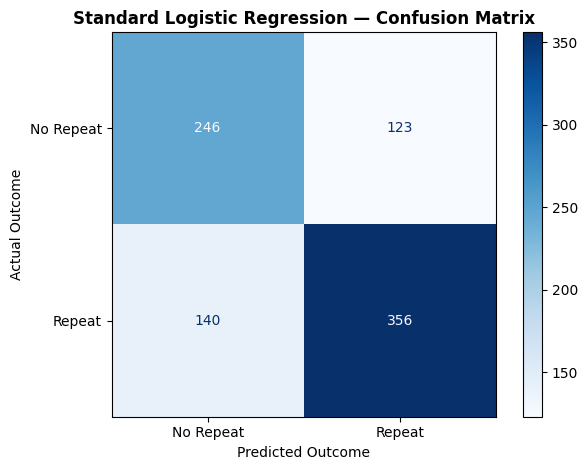

In [34]:
# ============================================================
# CONFUSION MATRIX — STANDARD LOGISTIC REGRESSION
# ============================================================

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_logistic,
    display_labels=[
        "No Repeat",
        "Repeat"
    ],
    cmap="Blues",
    values_format="d"
)

plt.title(
    "Standard Logistic Regression — Confusion Matrix",
    fontweight="bold"
)

plt.xlabel("Predicted Outcome")
plt.ylabel("Actual Outcome")

plt.tight_layout()
plt.show()

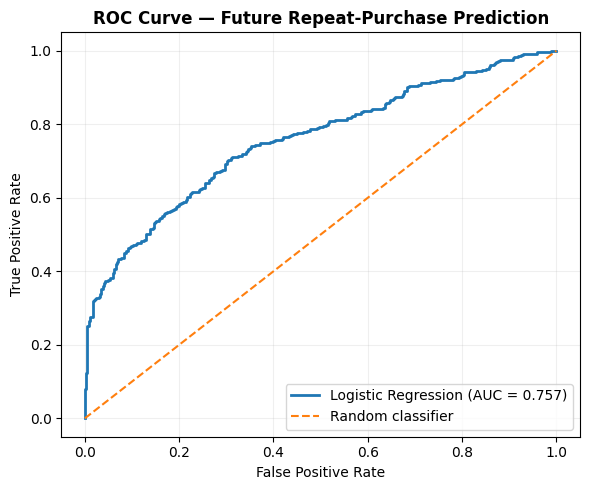

In [35]:
# ============================================================
# ROC CURVE — STANDARD LOGISTIC REGRESSION
# ============================================================

import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

# Calculate false-positive and true-positive rates
# across different probability thresholds.
fpr, tpr, thresholds = roc_curve(
    y_test,
    y_prob_logistic
)

auc_value = roc_auc_score(
    y_test,
    y_prob_logistic
)

plt.figure(figsize=(6, 5))

# ROC curve
plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"Logistic Regression (AUC = {auc_value:.3f})"
)

# Random-classifier reference line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title(
    "ROC Curve — Future Repeat-Purchase Prediction",
    fontweight="bold"
)

plt.legend(loc="lower right")
plt.grid(alpha=0.20)

plt.tight_layout()
plt.show()

In [36]:
# ============================================================
# COMPARE MODEL ACCURACY WITH A SIMPLE MAJORITY-CLASS BASELINE
# ============================================================

# The majority-class baseline predicts the most common class
# for every test customer.
#
# This gives us a simple benchmark to determine whether the
# Logistic Regression model adds predictive value.

majority_class = y_train.mode()[0]

baseline_predictions = np.full(
    len(y_test),
    majority_class
)

baseline_accuracy = accuracy_score(
    y_test,
    baseline_predictions
)

print(
    "Majority-class baseline accuracy:",
    round(baseline_accuracy, 4)
)

print(
    "Standard Logistic Regression accuracy:",
    round(accuracy_logistic, 4)
)

print(
    "Accuracy improvement:",
    round(accuracy_logistic - baseline_accuracy, 4)
)

Majority-class baseline accuracy: 0.5734
Standard Logistic Regression accuracy: 0.696
Accuracy improvement: 0.1225


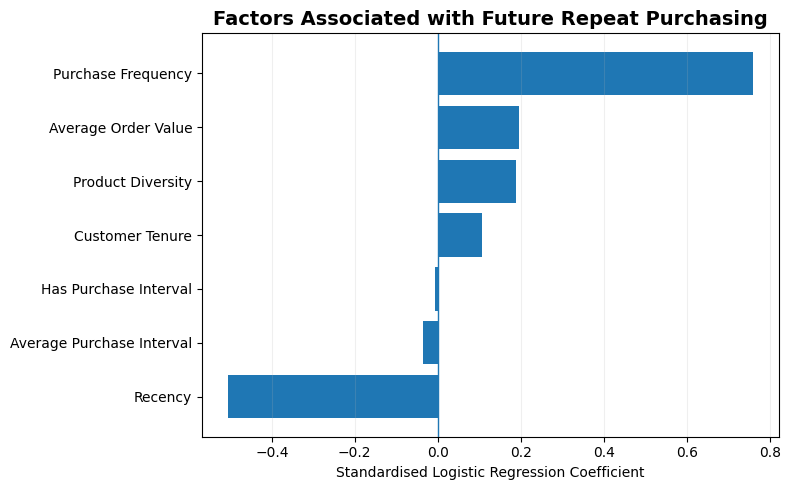

In [37]:
# ============================================================
# VISUALISE STANDARD LOGISTIC REGRESSION COEFFICIENTS
# ============================================================

import matplotlib.pyplot as plt
import pandas as pd

# Use the coefficients from the fitted Standard Logistic Regression model.
coef_plot = pd.DataFrame({
    "Predictor": final_predictors,
    "Coefficient": logistic_model.coef_[0]
})

# Rename predictors so the graph is easier for a business audience to read.
display_names = {
    "Log_Frequency": "Purchase Frequency",
    "Recency": "Recency",
    "Log_AverageOrderValue": "Average Order Value",
    "Log_ProductDiversity": "Product Diversity",
    "CustomerTenure": "Customer Tenure",
    "Log_AveragePurchaseInterval": "Average Purchase Interval",
    "HasPurchaseInterval": "Has Purchase Interval"
}

coef_plot["Predictor"] = coef_plot["Predictor"].replace(display_names)

# Sort coefficients for a clean horizontal plot.
coef_plot = coef_plot.sort_values("Coefficient")

plt.figure(figsize=(8, 5))

bars = plt.barh(
    coef_plot["Predictor"],
    coef_plot["Coefficient"]
)

# Zero line separates positive and negative associations.
plt.axvline(0, linewidth=1)

plt.title(
    "Factors Associated with Future Repeat Purchasing",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Standardised Logistic Regression Coefficient")
plt.ylabel("")

plt.grid(axis="x", alpha=0.20)

plt.tight_layout()
plt.show()